# Lab 06: Naïve Bayes Classifiers on the SMS Spam Collection
**Dataset:** `spam.csv` (SMS Spam Collection, Kaggle/UCI): 5,572 text messages labelled `ham` (normal) or `spam`.

**Plan**
1. Load data, handle missing values and duplicates
2. Split 80% train / 20% test
3. Build the features each variant needs
   - Bernoulli → binary word features
   - Multinomial → word counts
   - Gaussian → continuous numeric features (message length, digits, capitals, ...)
4. Train and evaluate each model: accuracy, precision, recall, F1
5. Compare the three variants

## Step 1: Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import BernoulliNB, MultinomialNB, GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
import warnings; warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

## Step 2: Load the dataset

In [2]:
df = pd.read_csv("spam.csv", encoding="latin-1")
print("Shape:", df.shape)
df.head()

Shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN


## Step 3: Handle missing data and duplicates
The file has three empty extra columns (`Unnamed: 2-4`). We keep only the label (`v1`) and message (`v2`), then drop missing rows and exact duplicate messages.

In [3]:
print("Missing values per column:")
print(df.isnull().sum())

df = df[["v1", "v2"]].rename(columns={"v1": "label", "v2": "text"})   # drop the empty columns
df = df.dropna(subset=["label", "text"])                              # drop rows with missing label/text
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)                      # duplicates would leak between train and test
print(f"\nDuplicates removed: {before - len(df)}  ->  {len(df)} messages left")

df["target"] = (df["label"] == "spam").astype(int)                    # ham = 0, spam = 1
print(df["label"].value_counts())

Missing values per column:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Duplicates removed: 403  ->  5169 messages left
label
ham     4516
spam     653
Name: count, dtype: int64


## Step 4: Build the numeric features (for Gaussian NB)
Gaussian NB needs **continuous** numbers, so we turn each message into measurable properties. We also add yes/no (categorical) flags, so the dataset has both feature types as the lab asks.

In [4]:
def make_numeric_features(texts):
    s = pd.Series(texts)
    out = pd.DataFrame({
        # continuous features
        "msg_length":      s.str.len(),
        "word_count":      s.str.split().str.len(),
        "digit_count":     s.str.count(r"\d"),
        "upper_ratio":     s.apply(lambda t: sum(c.isupper() for c in t) / max(len(t), 1)),
        "special_chars":   s.str.count(r"[^\w\s]"),
        "avg_word_length": s.apply(lambda t: np.mean([len(w) for w in t.split()]) if t.split() else 0),
        # categorical (yes/no) features
        "has_url":         s.str.contains(r"http|www\.|\.com", case=False).astype(int),
        "has_currency":    s.str.contains(r"[$£€]").astype(int),
        "has_long_number": s.str.contains(r"\d{5,}").astype(int),
    })
    return out

CONT_COLS = ["msg_length", "word_count", "digit_count", "upper_ratio", "special_chars", "avg_word_length"]
make_numeric_features(df["text"].head(3))

,msg_length,word_count,digit_count,upper_ratio,special_chars,avg_word_length,has_url,has_currency,has_long_number
0,111,20,0,0.027027,9,4.600000,0,0,0
1,29,6,0,0.068966,6,4.000000,0,0,0
2,155,28,25,0.064516,6,4.571429,0,0,1


## Step 5: Train / test split (80% / 20%)
Stratified, so spam makes up the same share of both sets. We split **before** building any features so the test data never influences training.

In [5]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=RANDOM_STATE, stratify=df["target"])
y_train, y_test = train_df["target"].values, test_df["target"].values
print("Train:", len(train_df), "| Test:", len(test_df))
print("Spam share  train: %.1f%%  test: %.1f%%" % (100*y_train.mean(), 100*y_test.mean()))

Train: 4135 | Test: 1034
Spam share  train: 12.6%  test: 12.7%


## Step 6: Preprocess features for each variant

In [6]:
# --- Bernoulli: binary features (word present = 1, absent = 0)
vec_bin = CountVectorizer(binary=True, stop_words="english", min_df=2)
X_train_bin = vec_bin.fit_transform(train_df["text"])      # fit on TRAIN only
X_test_bin  = vec_bin.transform(test_df["text"])

# --- Multinomial: word counts
vec_cnt = CountVectorizer(stop_words="english", min_df=2)
X_train_cnt = vec_cnt.fit_transform(train_df["text"])
X_test_cnt  = vec_cnt.transform(test_df["text"])

# --- Gaussian: continuous numeric features, scaled
num_train = make_numeric_features(train_df["text"].values)
num_test  = make_numeric_features(test_df["text"].values)
scaler = StandardScaler().fit(num_train[CONT_COLS])
num_train[CONT_COLS] = scaler.transform(num_train[CONT_COLS])
num_test[CONT_COLS]  = scaler.transform(num_test[CONT_COLS])

print("Bernoulli features :", X_train_bin.shape[1], "binary word features")
print("Multinomial features:", X_train_cnt.shape[1], "word-count features")
print("Gaussian features  :", num_train.shape[1], "numeric features:", list(num_train.columns))

Bernoulli features : 3049 binary word features
Multinomial features: 3049 word-count features
Gaussian features  : 9 numeric features: ['msg_length', 'word_count', 'digit_count', 'upper_ratio', 'special_chars', 'avg_word_length', 'has_url', 'has_currency', 'has_long_number']


## Step 7: Evaluation helper
One function so every model is scored the same way (accuracy, precision, recall, F1 for the **spam** class) and a confusion matrix is drawn.

In [7]:
results = []

def evaluate(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1-score":  f1_score(y_test, y_pred),
    })
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))
    plt.figure(figsize=(4, 3.4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
                cbar=False, xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    plt.title(name); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout(); plt.show()

## Step 8a: Bernoulli Naïve Bayes

=== Bernoulli NB ===
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.99      0.89      0.94       131

    accuracy                           0.99      1034
   macro avg       0.99      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034



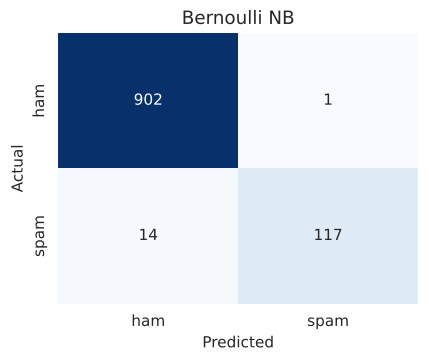

In [8]:
bnb = BernoulliNB()
bnb.fit(X_train_bin, y_train)
evaluate("Bernoulli NB", bnb, X_test_bin, y_test)

## Step 8b: Multinomial Naïve Bayes

=== Multinomial NB ===
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.95      0.92      0.94       131

    accuracy                           0.98      1034
   macro avg       0.97      0.96      0.96      1034
weighted avg       0.98      0.98      0.98      1034



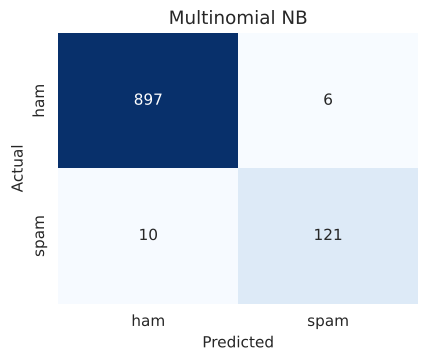

In [9]:
mnb = MultinomialNB(alpha=1.0)
mnb.fit(X_train_cnt, y_train)
evaluate("Multinomial NB", mnb, X_test_cnt, y_test)

In [10]:
# Words the Multinomial model links most strongly to spam
words = np.array(vec_cnt.get_feature_names_out())
gap = mnb.feature_log_prob_[1] - mnb.feature_log_prob_[0]
pd.DataFrame({"spam word": words[np.argsort(gap)[::-1][:10]],
              "strength":  np.sort(gap)[::-1][:10].round(2)})

,spam word,strength
0,claim,5.18
1,prize,5.08
2,150p,4.67
3,nokia,4.63
4,tone,4.50
5,www,4.46
6,18,4.44
7,16,4.41
8,guaranteed,4.35
9,500,4.35


## Step 8c: Gaussian Naïve Bayes

=== Gaussian NB ===
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       903
        spam       0.93      0.87      0.90       131

    accuracy                           0.97      1034
   macro avg       0.95      0.93      0.94      1034
weighted avg       0.97      0.97      0.97      1034



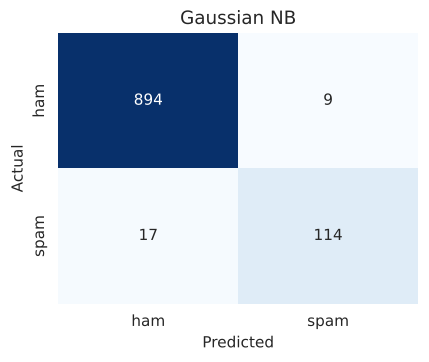

In [11]:
gnb = GaussianNB()
gnb.fit(num_train, y_train)
evaluate("Gaussian NB", gnb, num_test, y_test)

## Step 9: Comparison of the three variants

In [12]:
res = pd.DataFrame(results).set_index("Model").round(3)
res

,Accuracy,Precision,Recall,F1-score
Model,,,,
Bernoulli NB,0.985,0.992,0.893,0.940
Multinomial NB,0.985,0.953,0.924,0.938
Gaussian NB,0.975,0.927,0.870,0.898


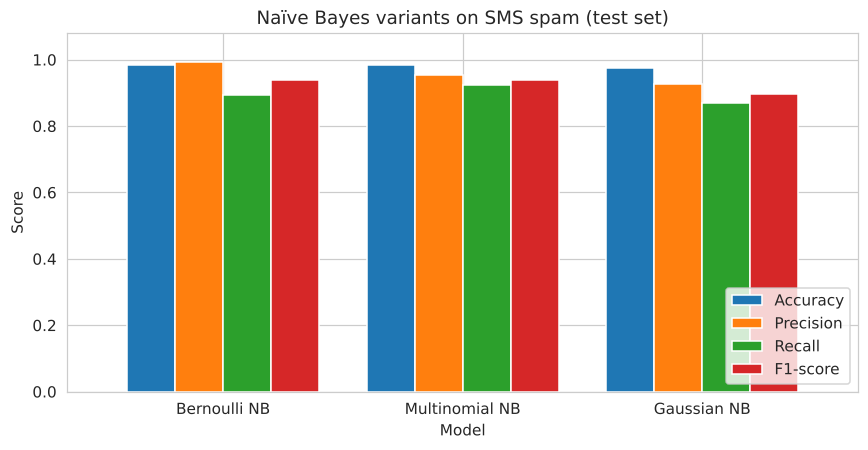

In [13]:
res.plot.bar(figsize=(8, 4.2), rot=0, width=0.8)
plt.ylim(0, 1.08); plt.ylabel("Score"); plt.title("Naïve Bayes variants on SMS spam (test set)")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## Step 10: Analysis (what the results mean)
The test set has 1,034 messages, of which 131 are spam. Spam is only ~13% of the data, so **accuracy alone is misleading** (always answering "ham" would already score 87%). Precision, recall and F1 for the spam class matter more.

| Model | Spam caught (recall) | Normal messages wrongly flagged | Reading |
|---|---|---|---|
| Bernoulli NB | 89.3% (117 of 131) | 1 | Almost never blocks a real message (precision 99.2%), but lets more spam through |
| Multinomial NB | 92.4% (121 of 131) | 6 | Catches the most spam, at the cost of a few false alarms |
| Gaussian NB | 87.0% (114 of 131) | 9 | Weakest on every metric |

- **Best overall: Bernoulli and Multinomial are effectively tied** (F1 0.940 vs 0.938, accuracy 98.5% for both). Both read the *words* in the message, which is the strongest spam signal (top spam words: claim, prize, 150p, nokia, tone, www, guaranteed).
- **Choosing between them depends on the cost of a mistake:** for a spam filter where losing a real message is worse than seeing some spam, Bernoulli is better; to catch as much spam as possible, Multinomial is better.
- **Gaussian NB is lowest** (accuracy 97.5%, F1 0.898). It only sees 9 summary numbers per message (length, digits, capitals, ...) and not the words, and counts like these are not truly bell-shaped. It still does well because spam has clear patterns (long numbers, many digits, currency symbols).

**Conclusion:** the variant should match the feature type. Word features (binary or counts) → Bernoulli / Multinomial, which win here. Continuous measurements → Gaussian, which works but loses information when the signal is mostly in the words.
